# 02 — Machine Learning de Saúde Operacional — FINAL

## Objetivo

Construir um primeiro modelo funcional para responder:

> **A máquina está operando de forma aderente ao padrão aprendido e, se não, quais fatores estão mais fora desse padrão?**

O modelo gera:

- **Score de Saúde Operacional: 0–100**
- status operacional
- lista dos fatores mais desviantes
- explicação textual
- ambiente de teste manual no final

### Interpretação correta

O score mede **aderência ao perfil operacional aprendido**.  
Ele **não é** probabilidade de falha, incêndio ou vida útil restante.

### Decisão metodológica

A EDA mostrou que o Tümosan é a base principal para construir o primeiro perfil operacional.  
O Fendt é útil para validação de domínio/compatibilidade, e o New Holland para testes controlados de anomalias. Eles não são misturados linha a linha no treinamento deste perfil.

Para permitir um teste manual com valores de sensores, esta versão usa **medianas de janelas de 60 s** das sete variáveis recomendadas pela EDA. Assim, os valores digitados no ambiente de teste têm a mesma semântica das features usadas no treinamento.


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import re
import json
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler

RANDOM_STATE = 42
JANELA_SEGUNDOS = 60

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 180)


# Guia leigo das variáveis do Machine Learning

O modelo observa sete sinais ao mesmo tempo. Eles não são tratados como regras isoladas; o objetivo é entender se **a combinação dos sinais** se parece com o comportamento aprendido.

| Variável                  | Nome simples                            | Significado leigo                                                                                                                                       |
| ------------------------- | --------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `EngCoolantTemp`          | Temperatura do líquido de arrefecimento | Temperatura do fluido que ajuda a retirar calor do motor. Sozinha não define falha; deve ser interpretada junto com esforço, rotação, óleo e histórico. |
| `EngOilTemp1`             | Temperatura do óleo                     | Mostra o quanto o óleo de lubrificação está aquecido durante o trabalho do motor.                                                                       |
| `EngOilPress`             | Pressão do óleo                         | Mostra a pressão com que o sistema de lubrificação faz o óleo circular. **Não é nível/quantidade de óleo.**                                             |
| `ActualEngine_PercTorque` | Torque do motor (%)                     | Indica quanto esforço o motor está entregando em relação à referência. Torque alto pode ser normal em trabalho pesado.                                  |
| `EngineSpeed`             | RPM                                     | RPM significa rotações por minuto: quantas voltas o motor realiza em um minuto. Representa o regime de funcionamento do motor.                          |
| `EngFuelRate`             | Taxa de combustível                     | Indica quanto combustível está sendo utilizado durante a operação e ajuda a representar a demanda do motor.                                             |
| `WheelBasedVehicleSpeed`  | Velocidade da máquina                   | Velocidade calculada a partir do movimento das rodas e usada como contexto da operação.                                                                 |

## Como o modelo usa essas informações

Ele não aprende uma regra do tipo “temperatura acima de X = ruim”. Ele aprende o **padrão multivariado**. Uma temperatura pode ser normal com determinado torque, RPM e consumo, mas formar uma combinação incomum em outro contexto.

Quando o score cai, a explicação procura os fatores mais distantes da referência. Se nenhum fator isolado estiver muito distante, mas a combinação for incomum, o resultado informa que existe um **desvio multivariado**.

> O dataset não fornece diretamente o nível físico de óleo. O sinal disponível é `EngOilPress`, isto é, **pressão do óleo**.


## 1 — Localização automática do projeto


In [2]:
def localizar_raiz():
    atual = Path.cwd().resolve()
    for p in [atual, *atual.parents]:
        if (p / "data" / "raw").exists():
            return p
    raise FileNotFoundError(
        "Não encontrei data/raw. Execute o notebook dentro do repositório do projeto."
    )

ROOT = localizar_raiz()
RAW = ROOT / "data" / "raw"
ASSETS = ROOT / "ml_assets"
OUT = ROOT / "data" / "processed" / "saude_operacional"

ASSETS.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)


ROOT: C:\Users\Kevin\OneDrive\Desktop\maia-intelligence-NEXT


## 2 — Variáveis definidas pela EDA

A EDA recomendou como núcleo do primeiro modelo Tümosan:

- `EngCoolantTemp`
- `EngOilTemp1`
- `EngOilPress`
- `ActualEngine_PercTorque`
- `EngineSpeed`
- `EngFuelRate`
- `WheelBasedVehicleSpeed`

`ATSTemp` não entra como temperatura ambiente.  
Sensores de draft também ficam fora deste primeiro modelo devido às limitações de qualidade observadas na EDA.


In [3]:
VARIAVEIS = [
    "EngCoolantTemp",
    "EngOilTemp1",
    "EngOilPress",
    "ActualEngine_PercTorque",
    "EngineSpeed",
    "EngFuelRate",
    "WheelBasedVehicleSpeed",
]

ROTULOS = {
    "EngCoolantTemp": "Temperatura do coolant (°C)",
    "EngOilTemp1": "Temperatura do óleo (°C)",
    "EngOilPress": "Pressão do óleo",
    "ActualEngine_PercTorque": "Torque do motor (%)",
    "EngineSpeed": "Rotação do motor (RPM)",
    "EngFuelRate": "Consumo de combustível",
    "WheelBasedVehicleSpeed": "Velocidade do trator",
}


## 3 — Carregamento das 10 sessões Tümosan


In [4]:
def numero_field(path):
    m = re.search(r"FIELD_(\d+)", path.name, re.I)
    return int(m.group(1)) if m else 999

arquivos = sorted((RAW / "tumosan").rglob("*.tab"), key=numero_field)

if not arquivos:
    raise FileNotFoundError("Nenhum .tab encontrado em data/raw/tumosan.")

sessoes = []

for p in arquivos:
    df = pd.read_csv(p, sep="\t")

    faltantes = [c for c in ["time_ms", *VARIAVEIS] if c not in df.columns]
    if faltantes:
        raise ValueError(f"{p.name}: colunas ausentes: {faltantes}")

    x = df[["time_ms", *VARIAVEIS]].copy()
    x["SESSAO"] = f"FIELD_{numero_field(p)}"

    x["time_ms"] = pd.to_numeric(x["time_ms"], errors="coerce")
    for c in VARIAVEIS:
        x[c] = pd.to_numeric(x[c], errors="coerce")

    sessoes.append(x)

bruto = pd.concat(sessoes, ignore_index=True)

print("Linhas:", f"{len(bruto):,}")
print("Sessões:", bruto["SESSAO"].nunique())
display(bruto.head())


Linhas: 889,255
Sessões: 10


,time_ms,EngCoolantTemp,EngOilTemp1,EngOilPress,ActualEngine_PercTorque,EngineSpeed,EngFuelRate,WheelBasedVehicleSpeed,SESSAO
0,0,76,62.750,416,75,2225.0,24.55,8,FIELD_1
1,100,76,62.625,416,74,2236.0,24.25,8,FIELD_1
2,200,76,62.625,416,72,2249.0,23.80,8,FIELD_1
3,300,76,62.625,416,71,2256.5,23.30,8,FIELD_1
4,400,76,62.625,416,69,2261.5,23.25,8,FIELD_1


## 4 — Limpeza conservadora

Não criamos limites mecânicos universais.

Apenas:

- removemos linhas sem tempo;
- tratamos `EngOilPress <= 0` como ausente para o ML, pois a EDA encontrou zeros isolados compatíveis com dropout/default;
- preservamos torque acima de 100%, pois a própria documentação da base permite essa ocorrência.


In [5]:
dados = bruto.copy()
dados = dados.dropna(subset=["time_ms"])

dados.loc[dados["EngOilPress"] <= 0, "EngOilPress"] = np.nan

print("Cobertura após tratamento:")
display((dados[VARIAVEIS].notna().mean() * 100).round(2).to_frame("cobertura_%"))


Cobertura após tratamento:


,cobertura_%
EngCoolantTemp,100.0
EngOilTemp1,100.0
EngOilPress,100.0
ActualEngine_PercTorque,100.0
EngineSpeed,100.0
EngFuelRate,100.0
WheelBasedVehicleSpeed,100.0


## 5 — Construção de janelas de 60 segundos

Cada ponto usado pelo ML representa aproximadamente **um minuto de operação**.

Usamos a mediana de cada sinal dentro da janela. Isso reduz ruído instantâneo e mantém o ambiente de teste compreensível: ao testar manualmente, os valores devem representar aproximadamente o comportamento recente da máquina, e não necessariamente um único pacote CAN de 100 ms.


In [6]:
partes = []

for sessao, g in dados.groupby("SESSAO"):
    g = g.sort_values("time_ms").copy()

    inicio = g["time_ms"].min()
    g["JANELA"] = ((g["time_ms"] - inicio) / 1000 // JANELA_SEGUNDOS).astype(int)

    agg = g.groupby("JANELA")[VARIAVEIS].median().reset_index()
    agg["SESSAO"] = sessao
    agg["TEMPO_MIN"] = agg["JANELA"] * JANELA_SEGUNDOS / 60

    partes.append(agg)

janelas = pd.concat(partes, ignore_index=True)
janelas = janelas.dropna(subset=VARIAVEIS).reset_index(drop=True)

print("Janelas válidas:", len(janelas))
print("Sessões:", janelas["SESSAO"].nunique())
display(janelas.head())


Janelas válidas: 1487
Sessões: 10


,JANELA,EngCoolantTemp,EngOilTemp1,EngOilPress,ActualEngine_PercTorque,EngineSpeed,EngFuelRate,WheelBasedVehicleSpeed,SESSAO,TEMPO_MIN
0,0,76.0,64.000,412.0,54.0,1944.75,16.325,7.5,FIELD_1,0.0
1,1,75.0,66.000,328.0,10.0,900.00,1.950,0.0,FIELD_1,1.0
2,2,74.0,68.000,332.0,10.0,901.00,2.000,0.0,FIELD_1,2.0
3,3,76.0,69.875,396.0,65.0,1947.50,17.950,7.0,FIELD_1,3.0
4,4,76.0,71.250,384.0,43.0,1802.50,10.075,5.0,FIELD_1,4.0


## 6 — Perfil robusto de referência

Além do Isolation Forest, guardamos mediana e MAD de cada variável.

Isso tem duas funções diferentes:

1. o **Isolation Forest** mede o desvio multivariado;
2. o **perfil robusto** ajuda a explicar quais variáveis do teste estão mais distantes do comportamento aprendido.

A lista de fatores não deve ser interpretada como causalidade mecânica. Ela indica **quais sinais contribuíram para tornar aquele cenário operacional incomum**.


In [7]:
def criar_perfil_robusto(df, variaveis):
    perfil = {}

    for c in variaveis:
        s = df[c].dropna().astype(float)
        med = float(s.median())
        mad = float(np.median(np.abs(s - med)))
        escala = 1.4826 * mad

        if escala < 1e-9:
            escala = float(s.std())

        if not np.isfinite(escala) or escala < 1e-9:
            escala = 1.0

        perfil[c] = {
            "mediana": med,
            "escala_robusta": escala,
            "p05": float(s.quantile(0.05)),
            "p25": float(s.quantile(0.25)),
            "p75": float(s.quantile(0.75)),
            "p95": float(s.quantile(0.95)),
        }

    return perfil

perfil = criar_perfil_robusto(janelas, VARIAVEIS)

perfil_df = pd.DataFrame(perfil).T
perfil_df.index.name = "VARIAVEL"
display(perfil_df.round(2))


,mediana,escala_robusta,p05,p25,p75,p95
VARIAVEL,,,,,,
EngCoolantTemp,78.00,1.48,76.00,77.00,79.00,80.00
EngOilTemp1,89.62,3.80,78.13,86.88,92.06,102.35
EngOilPress,376.00,11.86,322.00,360.00,380.00,396.00
ActualEngine_PercTorque,69.00,16.31,9.00,48.00,76.00,89.00
EngineSpeed,1791.50,100.08,904.48,1716.00,1853.00,2065.50
EngFuelRate,16.10,2.93,1.90,11.54,17.59,20.64
WheelBasedVehicleSpeed,7.00,1.48,0.00,6.00,7.00,11.00


## 7 — Validação interna por sessão

Não fazemos split aleatório por linha, pois as observações são temporais.

Em cada rodada:

- 9 sessões treinam o detector;
- 1 sessão inteira fica fora;
- repetimos para todas as sessões.

Como a base não possui rótulos reais de falha, esta validação mede **estabilidade do perfil entre sessões normais observadas**, não acurácia de diagnóstico de falha.


In [8]:
def calibrar_score(anomaly, referencia):
    referencia = np.sort(np.asarray(referencia, dtype=float))
    anomaly = np.asarray(anomaly, dtype=float)

    percentil = np.searchsorted(
        referencia,
        anomaly,
        side="right"
    ) / len(referencia)

    return np.clip(100 * (1 - percentil), 0, 100)

validacoes = []

for sessao in sorted(janelas["SESSAO"].unique()):
    treino = janelas[janelas["SESSAO"] != sessao].copy()
    teste = janelas[janelas["SESSAO"] == sessao].copy()

    scaler = RobustScaler()
    Xtr = scaler.fit_transform(treino[VARIAVEIS])
    Xte = scaler.transform(teste[VARIAVEIS])

    modelo = IsolationForest(
        n_estimators=500,
        contamination="auto",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    modelo.fit(Xtr)

    anomaly_tr = -modelo.score_samples(Xtr)
    anomaly_te = -modelo.score_samples(Xte)

    teste["ANOMALY_SCORE"] = anomaly_te
    teste["SCORE_SAUDE"] = calibrar_score(anomaly_te, anomaly_tr)

    validacoes.append(teste)

validacao = pd.concat(validacoes, ignore_index=True)

resumo_validacao = (
    validacao.groupby("SESSAO")["SCORE_SAUDE"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(resumo_validacao)


,count,mean,median,min,max
SESSAO,,,,,
FIELD_1,81,24.75,19.49,0.14,54.69
FIELD_10,149,19.06,17.79,2.09,55.46
FIELD_2,235,62.91,69.17,1.52,99.76
FIELD_3,91,26.67,34.67,0.21,52.79
FIELD_4,118,44.61,49.82,1.75,67.93
FIELD_5,221,52.95,61.06,0.47,99.45
FIELD_6,94,7.76,7.14,1.58,18.38
FIELD_7,108,39.82,44.74,0.00,63.16
FIELD_8,303,70.08,75.84,1.27,96.11


## 8 — Treino do modelo final

Depois da validação, treinamos o artefato final usando todas as janelas Tümosan disponíveis.

O scaler e o detector ficam congelados para inferência.


In [9]:
scaler_final = RobustScaler()
X = scaler_final.fit_transform(janelas[VARIAVEIS])

modelo_final = IsolationForest(
    n_estimators=700,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
modelo_final.fit(X)

referencia_anomaly = -modelo_final.score_samples(X)

print("Modelo final treinado.")
print("Janelas:", len(janelas))
print("Features:", len(VARIAVEIS))


Modelo final treinado.
Janelas: 1487
Features: 7


## 9 — Função de inferência e explicação

### Status

Os cortes abaixo são **operacionais/provisórios**, não limites mecânicos validados:

- `>= 75`: Aderente
- `50–74`: Atenção
- `25–49`: Desvio relevante
- `< 25`: Desvio forte

### Explicação

O ranking dos fatores usa distância robusta em relação ao perfil aprendido.

Isso permite retornar frases como:

> Temperatura do óleo muito acima do padrão + pressão do óleo abaixo do padrão + torque elevado.

O sistema não afirma que uma dessas variáveis _causou_ uma falha.


In [10]:
def classificar_status(score):
    if score >= 75:
        return "ADERENTE"
    if score >= 50:
        return "ATENÇÃO"
    if score >= 25:
        return "DESVIO RELEVANTE"
    return "DESVIO FORTE"

def analisar_fatores(valores, perfil, top_n=4):
    fatores = []

    for var in VARIAVEIS:
        valor = float(valores[var])
        ref = perfil[var]

        z = (valor - ref["mediana"]) / ref["escala_robusta"]
        abs_z = abs(z)

        if valor < ref["p05"]:
            faixa = "abaixo do padrão observado"
        elif valor > ref["p95"]:
            faixa = "acima do padrão observado"
        else:
            faixa = "dentro da faixa central observada"

        fatores.append({
            "variavel": var,
            "nome": ROTULOS[var],
            "valor_teste": valor,
            "mediana_referencia": ref["mediana"],
            "p05": ref["p05"],
            "p95": ref["p95"],
            "desvio_robusto": z,
            "intensidade_desvio": abs_z,
            "leitura": faixa,
        })

    fatores = sorted(
        fatores,
        key=lambda x: x["intensidade_desvio"],
        reverse=True
    )

    return fatores[:top_n]

def prever_saude(valores, mostrar=True):
    faltantes = [v for v in VARIAVEIS if v not in valores]
    if faltantes:
        raise ValueError(f"Variáveis faltantes: {faltantes}")

    entrada = pd.DataFrame([{
        v: float(valores[v])
        for v in VARIAVEIS
    }])

    Xnovo = scaler_final.transform(entrada[VARIAVEIS])

    anomaly = float(-modelo_final.score_samples(Xnovo)[0])
    score = float(calibrar_score([anomaly], referencia_anomaly)[0])
    status = classificar_status(score)

    fatores = analisar_fatores(valores, perfil, top_n=4)

    # Só destacamos fatores suficientemente desviantes.
    relevantes = [
        f for f in fatores
        if f["intensidade_desvio"] >= 1.5
        or f["valor_teste"] < f["p05"]
        or f["valor_teste"] > f["p95"]
    ]

    if status == "ADERENTE" and not relevantes:
        decisao = (
            "Os principais sinais estão aderentes ao comportamento "
            "aprendido nas sessões de referência."
        )
    elif relevantes:
        trechos = []
        for f in relevantes:
            direcao = (
                "acima"
                if f["desvio_robusto"] > 0
                else "abaixo"
            )
            trechos.append(
                f"{f['nome']} = {f['valor_teste']:.2f} "
                f"({direcao} da referência; "
                f"mediana {f['mediana_referencia']:.2f})"
            )

        decisao = "Principais fatores fora do padrão: " + "; ".join(trechos) + "."
    else:
        decisao = (
            "O conjunto multivariado foi considerado incomum pelo modelo, "
            "mas nenhuma variável isolada apresentou desvio robusto forte. "
            "Isso sugere uma combinação operacional incomum."
        )

    resultado = {
        "score_saude": round(score, 2),
        "status": status,
        "anomaly_score": anomaly,
        "decisao": decisao,
        "fatores": fatores,
    }

    if mostrar:
        print("=" * 72)
        print("RESULTADO DO TESTE")
        print("=" * 72)
        print(f"SCORE DE SAÚDE OPERACIONAL: {score:.2f}/100")
        print(f"STATUS: {status}")
        print()
        print(decisao)

        tabela = pd.DataFrame(fatores)[[
            "nome",
            "valor_teste",
            "mediana_referencia",
            "p05",
            "p95",
            "desvio_robusto",
            "leitura",
        ]].copy()

        tabela.columns = [
            "Fator",
            "Valor teste",
            "Mediana referência",
            "P05",
            "P95",
            "Desvio robusto",
            "Leitura",
        ]

        display(tabela.round(2))

    return resultado


# 10 — AMBIENTE DE TESTE MANUAL

## Como usar

Altere **somente os valores abaixo** e execute a célula.

Eles devem representar aproximadamente a mediana observada no último minuto da máquina.

Você pode testar:

- uma variável ruim isolada;
- duas ou três variáveis alteradas;
- uma combinação operacional aparentemente plausível;
- valores próximos ao perfil normal.

A função retorna o score e mostra quais fatores mais se afastaram do padrão.


In [11]:
# ============================================================
# EDITE SOMENTE AQUI
# ============================================================

TESTE = {
    "EngCoolantTemp": 75.0,            # °C
    "EngOilTemp1": 85.0,               # °C
    "EngOilPress": 300.0,              # unidade original da base
    "ActualEngine_PercTorque": 70.0,    # %
    "EngineSpeed": 1800.0,              # RPM
    "EngFuelRate": 12.0,                # unidade original da base
    "WheelBasedVehicleSpeed": 6.0,      # unidade original da base
}

resultado = prever_saude(TESTE)


RESULTADO DO TESTE
SCORE DE SAÚDE OPERACIONAL: 11.43/100
STATUS: DESVIO FORTE

Principais fatores fora do padrão: Pressão do óleo = 300.00 (abaixo da referência; mediana 376.00); Temperatura do coolant (°C) = 75.00 (abaixo da referência; mediana 78.00).


,Fator,Valor teste,Mediana referência,P05,P95,Desvio robusto,Leitura
0,Pressão do óleo,300.0,376.00,322.00,396.00,-6.41,abaixo do padrão observado
1,Temperatura do coolant (°C),75.0,78.00,76.00,80.00,-2.02,abaixo do padrão observado
2,Consumo de combustível,12.0,16.10,1.90,20.64,-1.40,dentro da faixa central observada
3,Temperatura do óleo (°C),85.0,89.62,78.13,102.35,-1.22,dentro da faixa central observada


## 11 — Teste automático usando exatamente a mediana aprendida

Esta célula é um sanity check.  
Ela monta um cenário central usando as medianas reais do treinamento.

Não significa que todo ponto na mediana precise obter 100, mas o cenário deve ser reconhecido como altamente aderente ao perfil aprendido.


In [12]:
TESTE_MEDIANA = {
    v: perfil[v]["mediana"]
    for v in VARIAVEIS
}

resultado_mediana = prever_saude(TESTE_MEDIANA)


RESULTADO DO TESTE
SCORE DE SAÚDE OPERACIONAL: 96.64/100
STATUS: ADERENTE

Os principais sinais estão aderentes ao comportamento aprendido nas sessões de referência.


,Fator,Valor teste,Mediana referência,P05,P95,Desvio robusto,Leitura
0,Temperatura do coolant (°C),78.00,78.00,76.00,80.00,0.0,dentro da faixa central observada
1,Temperatura do óleo (°C),89.62,89.62,78.13,102.35,0.0,dentro da faixa central observada
2,Pressão do óleo,376.00,376.00,322.00,396.00,0.0,dentro da faixa central observada
3,Torque do motor (%),69.00,69.00,9.00,89.00,0.0,dentro da faixa central observada


## 12 — Experimento: descobrir impacto de cada variável

Esta célula altera **uma variável por vez** para o percentil 99 observado e mede o novo score.

Ela serve para entender a sensibilidade do modelo.  
Não é feature importance causal.


In [13]:
base_central = {
    v: perfil[v]["mediana"]
    for v in VARIAVEIS
}

experimentos = []

for var in VARIAVEIS:
    teste = base_central.copy()
    teste[var] = float(janelas[var].quantile(0.99))

    r = prever_saude(teste, mostrar=False)

    experimentos.append({
        "variavel_alterada": ROTULOS[var],
        "valor_p99": teste[var],
        "score_resultante": r["score_saude"],
        "status": r["status"],
    })

impacto = pd.DataFrame(experimentos).sort_values("score_resultante")
display(impacto)


,variavel_alterada,valor_p99,score_resultante,status
6,Velocidade do trator,14.00000,39.88,DESVIO RELEVANTE
1,Temperatura do óleo (°C),104.90125,47.75,DESVIO RELEVANTE
5,Consumo de combustível,23.60350,47.95,DESVIO RELEVANTE
0,Temperatura do coolant (°C),81.00000,48.15,DESVIO RELEVANTE
4,Rotação do motor (RPM),2202.49000,50.24,ATENÇÃO
2,Pressão do óleo,408.56000,55.82,ATENÇÃO
3,Torque do motor (%),94.00000,56.49,ATENÇÃO


## 13 — Visualização do teste manual contra a referência

Cada variável é convertida para desvio robusto.  
Quanto maior a distância de zero, mais distante ela está da mediana aprendida.


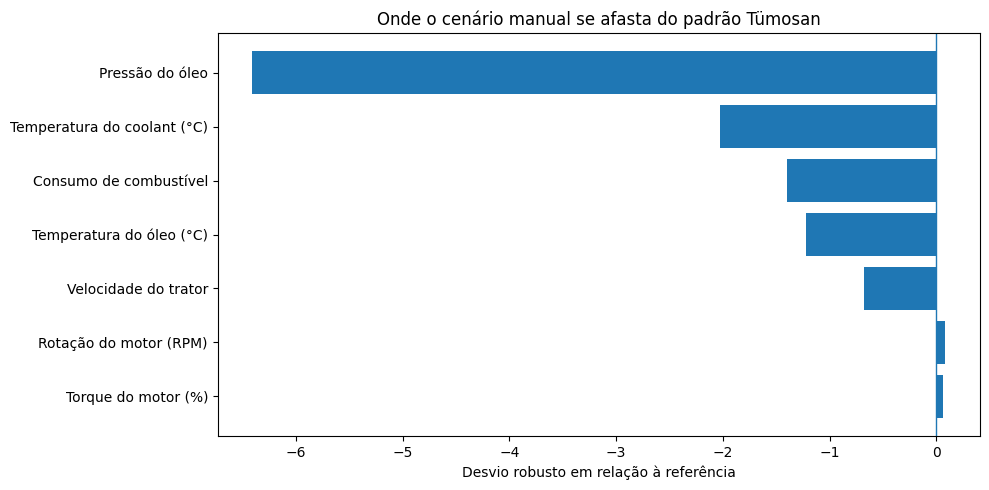

In [14]:
fatores_plot = analisar_fatores(TESTE, perfil, top_n=len(VARIAVEIS))
plot_df = pd.DataFrame(fatores_plot).sort_values("intensidade_desvio")

plt.figure(figsize=(10, 5))
plt.barh(plot_df["nome"], plot_df["desvio_robusto"])
plt.axvline(0, linewidth=1)
plt.xlabel("Desvio robusto em relação à referência")
plt.title("Onde o cenário manual se afasta do padrão Tümosan")
plt.tight_layout()
plt.show()


## 14 — Exportação do modelo

O artefato contém tudo o que a API precisa para reproduzir a inferência:

- Isolation Forest
- RobustScaler
- variáveis
- distribuição de referência do anomaly score
- perfil robusto
- metadados


In [15]:
artefato = {
    "versao": "1.0",
    "perfil_id": "TUMOSAN_81_110",
    "tipo": "saude_operacional_anomalia",
    "janela_segundos": JANELA_SEGUNDOS,
    "variaveis": VARIAVEIS,
    "rotulos": ROTULOS,
    "scaler": scaler_final,
    "modelo": modelo_final,
    "referencia_anomaly": referencia_anomaly,
    "perfil_robusto": perfil,
    "interpretacao": (
        "Score de aderência ao perfil operacional observado; "
        "não é probabilidade de falha/incêndio."
    ),
}

modelo_path = ASSETS / "modelo_saude_operacional_tumosan_final.pkl"

with open(modelo_path, "wb") as f:
    pickle.dump(artefato, f)

perfil_df.to_csv(
    OUT / "perfil_referencia_tumosan.csv"
)

resumo_validacao.to_csv(
    OUT / "validacao_leave_one_session_out.csv"
)

print("Modelo salvo em:", modelo_path)
print("Resultados salvos em:", OUT)


Modelo salvo em: C:\Users\Kevin\OneDrive\Desktop\maia-intelligence-NEXT\ml_assets\modelo_saude_operacional_tumosan_final.pkl
Resultados salvos em: C:\Users\Kevin\OneDrive\Desktop\maia-intelligence-NEXT\data\processed\saude_operacional


# Aprendizado progressivo: do baseline Tümosan ao perfil da própria máquina

O Tümosan será o **baseline inicial**, não a verdade permanente de todas as máquinas.

A evolução planejada é:

`Tümosan → máquina começa a operar → histórico próprio → dados confiáveis aprovados → perfil individual → atualizações versionadas`

## Três estágios

**INICIAL:** a máquina ainda não possui histórico suficiente e usa o baseline Tümosan/família.

**ADAPTANDO:** o sistema já possui histórico próprio suficiente para criar um segundo perfil e passa a observar, em paralelo, a aderência ao baseline e ao comportamento da própria unidade.

**INDIVIDUAL:** depois de histórico suficiente e confiável, o perfil da própria máquina torna-se a referência principal. O baseline inicial continua disponível como comparação e fallback.

## Proteção contra aprender um defeito como “normal”

Retroalimentar não significa treinar com tudo que chega. Toda janela entra no **histórico bruto**, mas uma janela anômala não deve automaticamente ensinar o modelo.

Caso contrário, uma degradação progressiva poderia ser incorporada ao baseline e deixar de gerar alerta. Por isso o fluxo separa:

`TELEMETRIA → INFERÊNCIA → HISTÓRICO → CANDIDATO A BASELINE → APROVAÇÃO → RETREINO VERSIONADO`

O retreino deve ocorrer em lote, e não a cada pacote CAN.


In [16]:
CONFIG_ADAPTACAO = {
    # Valores iniciais de engenharia; devem ser calibrados posteriormente.
    "min_janelas_para_adaptar": 300,
    "min_janelas_perfil_maduro": 1000,
    "score_minimo_para_candidato": 50,
    "max_janelas_historico_treino": 5000,
}

def avaliar_candidato_baseline(resultado):
    score = float(resultado["score_saude"])
    if score < CONFIG_ADAPTACAO["score_minimo_para_candidato"]:
        return {
            "aceitar": False,
            "motivo": "Preservar no histórico, mas não ensinar automaticamente como normal."
        }
    return {
        "aceitar": True,
        "motivo": "Janela candidata ao histórico normal da unidade."
    }

def estagio_perfil(qtd_janelas_aprovadas):
    if qtd_janelas_aprovadas < CONFIG_ADAPTACAO["min_janelas_para_adaptar"]:
        return "INICIAL"
    if qtd_janelas_aprovadas < CONFIG_ADAPTACAO["min_janelas_perfil_maduro"]:
        return "ADAPTANDO"
    return "INDIVIDUAL"

CONFIG_ADAPTACAO


{'min_janelas_para_adaptar': 300,
 'min_janelas_perfil_maduro': 1000,
 'score_minimo_para_candidato': 50,
 'max_janelas_historico_treino': 5000}

## Planejamento do INSERT de novas informações

A persistência deve separar três responsabilidades.

### `TELEMETRIA_MAQUINA`

Histórico com adulteração detectável do que chegou da máquina:
`machine_id`, início/fim da janela, sete sinais agregados, score, status, versão do modelo, perfil usado e qualidade dos dados.

### `BASELINE_CANDIDATO`

Janelas potencialmente confiáveis para ensinar o perfil individual:
`machine_id`, `telemetria_id`, score no momento da coleta, decisão de aceitação, motivo e data de inclusão.

### `PERFIL_MAQUINA`

Controle do aprendizado:
`machine_id`, versão, estágio (`INICIAL`, `ADAPTANDO`, `INDIVIDUAL`), quantidade de janelas aprovadas, data do último treino, artefato ativo e métricas de validação.

### Fluxo

```text
ESP32/CAN
   ↓
API → buffer de 60 s → janela
   ↓
INSERT TELEMETRIA_MAQUINA
   ↓
score + explicação
   ↓
dados confiáveis e não fortemente anômalos?
   ├─ não → permanece apenas no histórico
   └─ sim → INSERT BASELINE_CANDIDATO
                  ↓
          histórico suficiente?
                  ↓
        treinar candidato de perfil
                  ↓
       validar contra perfil anterior
                  ↓
       publicar nova versão somente
       se os critérios forem atendidos
```

Durante a adaptação, é recomendável manter **baseline inicial e perfil individual em paralelo**. A proporção exata entre eles não deve ser fixada agora como verdade; deve ser calibrada com validação e, futuramente, eventos de manutenção/inspeção.


In [17]:
def montar_registro_telemetria(
    machine_id, valores, resultado,
    timestamp_inicio, timestamp_fim,
    perfil_usado="TUMOSAN_81_110"
):
    return {
        "machine_id": machine_id,
        "timestamp_inicio": timestamp_inicio,
        "timestamp_fim": timestamp_fim,
        **{v: float(valores[v]) for v in VARIAVEIS},
        "score_saude": float(resultado["score_saude"]),
        "status": resultado["status"],
        "perfil_usado": perfil_usado,
        "modelo_versao": "1.0",
    }

# Exemplo de consulta do estágio:
JANELAS_APROVADAS_DA_MAQUINA = 0
print("Estágio atual:", estagio_perfil(JANELAS_APROVADAS_DA_MAQUINA))


Estágio atual: INICIAL


# 15 — Como isso entra no produto

No protótipo:

`CAN/J1939 → ESP32 → API → buffer de ~60 s → mediana dos sinais → modelo → score + fatores`

Exemplo de resposta da API:

```json
{
  "machine_profile": "TUMOSAN_81_110",
  "score_saude": 34.8,
  "status": "DESVIO RELEVANTE",
  "fatores": [
    {
      "variavel": "EngOilTemp1",
      "direcao": "acima do padrão"
    },
    {
      "variavel": "EngOilPress",
      "direcao": "abaixo do padrão"
    }
  ]
}
```

## Limitações que devem continuar explícitas

1. O Tümosan representa operação observada, não uma base de falhas reais.
2. O score é aderência estatística ao perfil, não probabilidade de quebra.
3. Os fatores explicativos mostram desvios, não causalidade.
4. Os limites de status são provisórios.
5. Fendt deve ser usado para avaliar diferença de domínio/compatibilidade, não para exigir o mesmo score.
6. New Holland deve ser usado posteriormente para testar sensibilidade a anomalias sintéticas.
7. Em produção, o ideal é evoluir de **perfil por família/modelo** para **histórico da própria unidade** conforme dados confiáveis forem acumulados.
